In [130]:
import pandas as pd
iv_table = pd.read_excel('./data/Online_Retail.xlsx')

iv_table.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [131]:
product_table = iv_table.copy()

In [132]:
product_table = product_table.drop('CustomerID', axis = 1)
product_table = product_table.drop('Country', axis = 1)
product_table = product_table.drop('Description', axis = 1)

In [133]:
product_table.head()

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice
0,536365,85123A,6,2010-12-01 08:26:00,2.55
1,536365,71053,6,2010-12-01 08:26:00,3.39
2,536365,84406B,8,2010-12-01 08:26:00,2.75
3,536365,84029G,6,2010-12-01 08:26:00,3.39
4,536365,84029E,6,2010-12-01 08:26:00,3.39


In [134]:
product_table.isnull().sum()

InvoiceNo      0
StockCode      0
Quantity       0
InvoiceDate    0
UnitPrice      0
dtype: int64

In [135]:
# 판매량이 양수인거만 남김 --> 즉, 취소 및 반품은 포함 X
product_table = product_table[product_table['Quantity'] > 0]

In [136]:
product_table.head()

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice
0,536365,85123A,6,2010-12-01 08:26:00,2.55
1,536365,71053,6,2010-12-01 08:26:00,3.39
2,536365,84406B,8,2010-12-01 08:26:00,2.75
3,536365,84029G,6,2010-12-01 08:26:00,3.39
4,536365,84029E,6,2010-12-01 08:26:00,3.39


In [137]:
product_table[product_table['UnitPrice'] <= 0].shape
# 개당가격이 0이하 인거 찍어보니 1181개 행이 있음

(1181, 5)

In [138]:
#정상 거래만 남기고 
product_table = product_table[product_table['UnitPrice'] > 0]
# 다시 찍어봐서 잘 지워졌나 확인
product_table[product_table['UnitPrice'] <= 0].shape


(0, 5)

In [139]:
# 날짜 --> 년 월 일 시간으로 찢기
product_table['InvoiceDate'] = pd.to_datetime(product_table['InvoiceDate'])

product_table['year'] = product_table.InvoiceDate.apply(lambda x: x.year)
product_table['month'] = product_table.InvoiceDate.apply(lambda x: x.month)
product_table['day'] = product_table.InvoiceDate.apply(lambda x: x.day)
product_table['hour'] = product_table.InvoiceDate.apply(lambda x: x.hour)

product_table.head()

,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,year,month,day,hour
0,536365,85123A,6,2010-12-01 08:26:00,2.55,2010,12,1,8
1,536365,71053,6,2010-12-01 08:26:00,3.39,2010,12,1,8
2,536365,84406B,8,2010-12-01 08:26:00,2.75,2010,12,1,8
3,536365,84029G,6,2010-12-01 08:26:00,3.39,2010,12,1,8
4,536365,84029E,6,2010-12-01 08:26:00,3.39,2010,12,1,8


In [140]:
# 상품의 월간 판매량
# 재고번호, 년, 월이 같은것끼리 묶어서, 수량을 합친 다음, 인덱스가 아니라 컬럼으로 들어간다
monthly_sales = product_table.groupby(['StockCode',
                                       'year',
                                       'month'])['Quantity'].sum().reset_index()

monthly_sales.head()

,StockCode,year,month,Quantity
0,10002,2010,12,251
1,10002,2011,1,340
2,10002,2011,2,52
3,10002,2011,3,28
4,10002,2011,4,189


In [141]:
# 월별 판매량을 상품별로 요약한다
product_df = monthly_sales.groupby('StockCode').agg(How_Long_Months = ('Quantity', 'count'), 			# 상품이 몇개월간 판매됐는가
                                                    Total_Quantity = ('Quantity', 'sum'),				# 전체 기간동안 몇개 팔렸는가
                                                    Peak_Month_Quantity = ('Quantity', 'max'),			# 제일 많이 판 달에는 몇개 팔렸는가
                                                    Monthly_Mean = ('Quantity', 'mean'),				# 팔린 달만 따졌을 때 월평균 판매량
                                                    Monthly_Std = ('Quantity', 'std')).reset_index()	# 월별 판매량이 평균에서 얼마나 들쭉날쭉한가 --> 표준편차

product_df.head()

,StockCode,How_Long_Months,Total_Quantity,Peak_Month_Quantity,Monthly_Mean,Monthly_Std
0,10002,5,860,340,172.000000,132.183584
1,10080,7,303,91,43.285714,33.119553
2,10120,10,193,49,19.300000,15.520954
3,10125,12,1296,213,108.000000,67.612532
4,10133,10,2867,830,286.700000,304.265984


In [142]:
# 제일 많이 판 달에 판 개수가 전체 판매개수에서 차지하는 비율 --> 즉, 특정 한달에 얼마나 많이 몰렸나
product_df['Peak_Month_Ratio'] = (product_df['Peak_Month_Quantity']/product_df['Total_Quantity'])

# 월별로 판매량이 얼마나 변동되었나
product_df['Monthly_Sales_Change'] = (product_df['Monthly_Std']/product_df['Monthly_Mean'])
#근데 한달만 판매됐다면, 변동 자체가 없으므로 결측치 발생 --> 0으로 처리
product_df['Monthly_Sales_Change'] = (product_df['Monthly_Sales_Change'].fillna(0))


product_df.head()

,StockCode,How_Long_Months,Total_Quantity,Peak_Month_Quantity,Monthly_Mean,Monthly_Std,Peak_Month_Ratio,Monthly_Sales_Change
0,10002,5,860,340,172.000000,132.183584,0.395349,0.768509
1,10080,7,303,91,43.285714,33.119553,0.300330,0.765138
2,10120,10,193,49,19.300000,15.520954,0.253886,0.804194
3,10125,12,1296,213,108.000000,67.612532,0.164352,0.626042
4,10133,10,2867,830,286.700000,304.265984,0.289501,1.061270


In [143]:
product_df[['How_Long_Months', 'Peak_Month_Ratio', 'Monthly_Sales_Change']].describe()

,How_Long_Months,Peak_Month_Ratio,Monthly_Sales_Change
count,3922.000000,3922.000000,3922.000000
mean,8.686639,0.389850,0.809671
std,4.162654,0.235068,0.442761
min,1.000000,0.101177,0.000000
25%,5.000000,0.213891,0.526819
50%,10.000000,0.320438,0.759954
75%,13.000000,0.500000,1.066835
max,13.000000,1.000000,3.047564


In [144]:
features = ['How_Long_Months',
            'Peak_Month_Ratio',
            'Monthly_Sales_Change']

X = product_df[features]

In [145]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [146]:
def visualize_silhouette(cluster_lists, X_features): 
  
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_samples, silhouette_score

    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import numpy as np
    
    # 입력값으로 클러스터링 갯수들을 리스트로 받아서, 각 갯수별로 클러스터링을 적용하고 실루엣 개수를 구함
    n_cols = len(cluster_lists)
    
    # plt.subplots()으로 리스트에 기재된 클러스터링 수만큼의 sub figures를 가지는 axs 생성 
    fig, axs = plt.subplots(figsize=(4*n_cols, 4), nrows=1, ncols=n_cols)
    
    # 리스트에 기재된 클러스터링 갯수들을 차례로 iteration 수행하면서 실루엣 개수 시각화
    for ind, n_cluster in enumerate(cluster_lists):
        
        # KMeans 클러스터링 수행하고, 실루엣 스코어와 개별 데이터의 실루엣 값 계산. 
        clusterer = KMeans(n_clusters = n_cluster, max_iter=500, random_state=0)
        cluster_labels = clusterer.fit_predict(X_features)
        
        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)
        
        y_lower = 10
        axs[ind].set_title('Number of Cluster : '+ str(n_cluster)+'\n' \
                          'Silhouette Score :' + str(round(sil_avg,3)) )
        axs[ind].set_xlabel("The silhouette coefficient values")
        axs[ind].set_ylabel("Cluster label")
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])  # Clear the yaxis labels / ticks
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
        
        # 클러스터링 갯수별로 fill_betweenx( )형태의 막대 그래프 표현. 
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels==i]
            ith_cluster_sil_values.sort()
            
            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i
            
            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, \
                                facecolor=color, edgecolor=color, alpha=0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10
            
        axs[ind].axvline(x=sil_avg, color="red", linestyle="--")

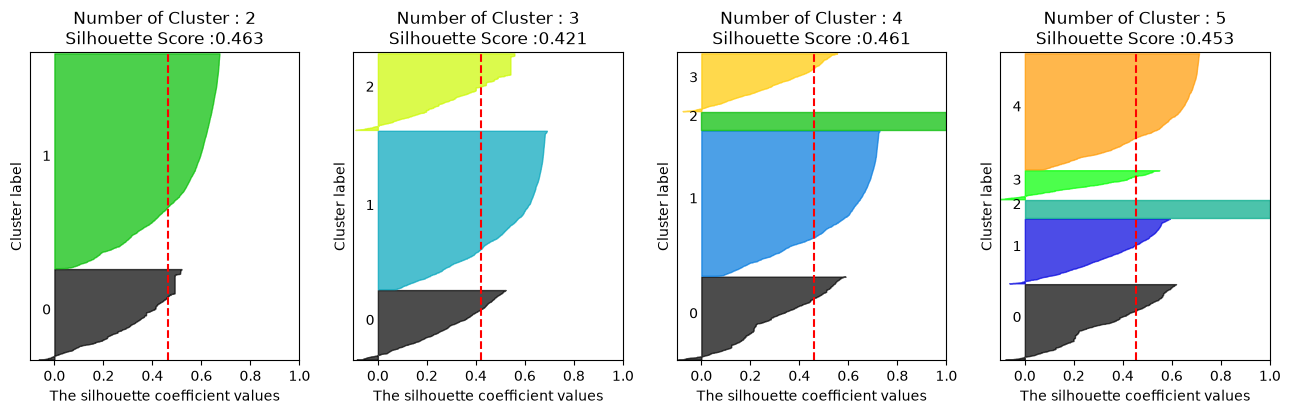

In [147]:
visualize_silhouette([2, 3, 4, 5], X_scaled)

# 실루엣 점수는 cluster 2개일때 가장 높긴 한데, 4개와 큰 차이가 없음
# 더 세밀한 분류를 위해 군집개수 4개로 선정

In [148]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 4,			
				init = 'k-means++',		
				max_iter = 500,			
				random_state = 0)


kmeans.fit(X_scaled)
			  


product_df['cluster'] = kmeans.labels_ #cluster컬럼 추가해서, 앞에 각 데이터가 몇번 군집에 속해있는지 컬럼 추가

product_df.head()

,StockCode,How_Long_Months,Total_Quantity,Peak_Month_Quantity,Monthly_Mean,Monthly_Std,Peak_Month_Ratio,Monthly_Sales_Change,cluster
0,10002,5,860,340,172.000000,132.183584,0.395349,0.768509,0
1,10080,7,303,91,43.285714,33.119553,0.300330,0.765138,0
2,10120,10,193,49,19.300000,15.520954,0.253886,0.804194,1
3,10125,12,1296,213,108.000000,67.612532,0.164352,0.626042,1
4,10133,10,2867,830,286.700000,304.265984,0.289501,1.061270,1


In [149]:
# cluster 별로 묶어서 각 features 별로 평균값 냄
product_df.groupby('cluster')[['How_Long_Months',
                               'Peak_Month_Ratio',
                               'Monthly_Sales_Change']].mean()

,How_Long_Months,Peak_Month_Ratio,Monthly_Sales_Change
cluster,,,
0,4.178172,0.503235,0.716100
1,11.626603,0.215434,0.703458
2,1.000000,1.000000,0.000000
3,10.178284,0.474843,1.462462


In [150]:
product_df['cluster'].value_counts().sort_index() # 각 군집에 속한 상품이 몇개인가

cluster
0    1072
1    1872
2     232
3     746
Name: count, dtype: int64

In [151]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df_cls = pd.DataFrame(X_pca,
                      columns=['ftr1', 'ftr2'])

df_cls['kmeans_label'] = kmeans.labels_ 	#Kmeans에서 쓴 군집번호를 PCA에서도 그대로 붙인다

df_cls.head()

,ftr1,ftr2,kmeans_label
0,-0.668654,-0.116886,0
1,-0.059502,-0.250518,0
2,0.605829,-0.208959,1
3,1.110019,-0.701166,1
4,0.637015,0.386347,1


In [152]:
print(pca.explained_variance_ratio_) 

[0.60613258 0.34474264]


In [153]:
centers = pca.transform(kmeans.cluster_centers_)

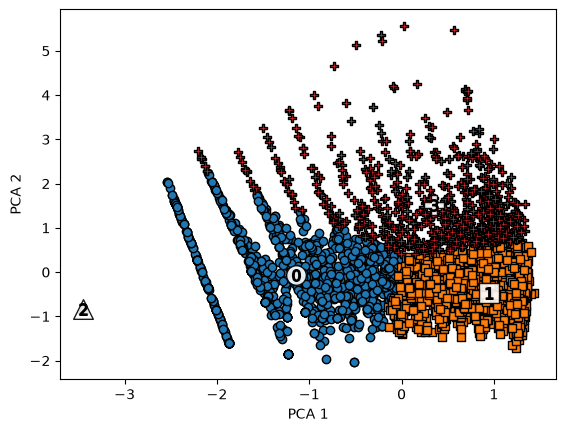

In [154]:
import numpy as np
import matplotlib.pyplot as plt

unique_labels = np.unique(kmeans.labels_)

markers = ['o', 's', '^', 'P', 'D', 'H', 'x']

for label in unique_labels:

    label_cluster = df_cls[
        df_cls['kmeans_label'] == label
    ]

    center = centers[label]

    # 군집 데이터
    plt.scatter(
        x=label_cluster['ftr1'],
        y=label_cluster['ftr2'],
        edgecolor='k',
        marker=markers[label]
    )

    # 군집 중심점 바깥 표시
    plt.scatter(
        x=center[0],
        y=center[1],
        s=200,
        color='white',
        alpha=0.9,
        edgecolor='k',
        marker=markers[label]
    )

    # 중심점에 군집 번호 표시
    plt.scatter(
        x=center[0],
        y=center[1],
        s=70,
        color='k',
        edgecolor='k',
        marker='$%d$' % label
    )

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')

plt.show()

In [155]:
############ 클러스터 2개로 했을 때 #####################

In [156]:
from sklearn.cluster import KMeans

kmeans_2 = KMeans(n_clusters = 2,			
				init = 'k-means++',		
				max_iter = 500,			
				random_state = 0)


kmeans_2.fit(X_scaled)
			  

df_cls_2 = pd.DataFrame(X_pca, 
                        columns=['ftr1', 'ftr2'])

df_cls_2['kmeans_label'] = kmeans_2.labels_

centers_2 = pca.transform(kmeans_2.cluster_centers_)

unique_labels_2 = np.unique(kmeans_2.labels_)

markers = ['o', 's']


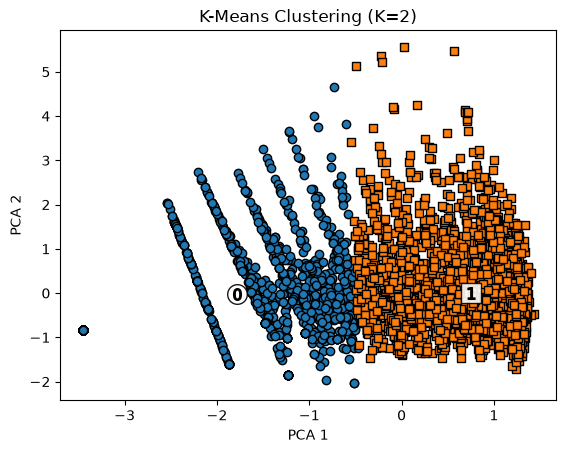

In [157]:
for label in unique_labels_2:

    label_cluster = df_cls_2[
        df_cls_2['kmeans_label'] == label
    ]

    center = centers_2[label]

    plt.scatter(
        x=label_cluster['ftr1'],
        y=label_cluster['ftr2'],
        edgecolor='k',
        marker=markers[label]
    )

    plt.scatter(
        x=center[0],
        y=center[1],
        s=200,
        color='white',
        alpha=0.9,
        edgecolor='k',
        marker=markers[label]
    )

    plt.scatter(
        x=center[0],
        y=center[1],
        s=70,
        color='k',
        edgecolor='k',
        marker='$%d$' % label
    )

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('K-Means Clustering (K=2)')

plt.show()